# The promise and an early warning

The previous two notebooks found that the late rate mostly measures the promise, and that the promise hides how long customers in different places actually wait. That leaves two practical questions:

1. **How should "slower than it should have been" be defined, if not against the promise?** The idea tested here is to build Olist's own expected delivery time for every route from recent history, and to judge each order against that instead of against the promised date.
2. **Can late orders be identified early enough to do something about them?**

The two turn out to be the same problem. An expected delivery time per route is also the most effective early-warning system tested here, and it beats a machine-learning model built for the purpose.

## Scope

Delivered orders purchased between January 2017 and August 2018. Expected delivery times are calculated from July 2017 onwards, so that every month has at least six months of history behind it, and the methods are evaluated on orders purchased in 2018.

In [1]:
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import os

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import roc_auc_score, average_precision_score

con = duckdb.connect("../olist.duckdb")

con.sql("""
    CREATE OR REPLACE VIEW model.v_delivery AS
    SELECT o.*, r.seller_state, r.customer_state, r.same_state, r.same_region, r.customer_region
    FROM model.fct_orders o
    LEFT JOIN model.dim_route r USING (route_key)
    WHERE purchase_date BETWEEN DATE '2017-01-01' AND DATE '2018-08-31'
""")

con.sql("""
    CREATE OR REPLACE TEMP VIEW delivery AS
    SELECT *,
        CASE WHEN distance_km <  200 THEN 1 WHEN distance_km <  500 THEN 2
             WHEN distance_km < 1000 THEN 3 WHEN distance_km < 2000 THEN 4
             WHEN distance_km IS NOT NULL THEN 5 ELSE 0 END AS distance_band
    FROM model.v_delivery
""")

def q(sql):
    return con.sql(sql).df()

def show(sql, n=30):
    con.sql(sql).show(max_rows=n)

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "font.size": 9,
})
BAND_NAMES = {1: "under 200 km", 2: "200-500 km", 3: "500-1000 km", 4: "1000-2000 km", 5: "2000 km and over"}
print("connected")

connected


---

## 1. Why one average cannot define "slow"

The simplest alternative to the promise would be a single expected delivery time - say, the platform average - and to call anything slower than that slow. The delivery analysis already shows why that fails: delivery time depends heavily on distance. A less obvious problem is that the **spread** of delivery times depends on distance too.

In [2]:
show("""
    SELECT
        distance_band,
        COUNT(*)                                                        AS orders,
        ROUND(AVG(delivery_days), 1)                                    AS avg_delivery,
        ROUND(STDDEV(delivery_days), 1)                                 AS sd_delivery,
        ROUND(AVG(promised_days), 1)                                    AS avg_promise,
        ROUND(AVG(promised_days) - AVG(delivery_days), 1)               AS slack_days,
        ROUND((AVG(promised_days) - AVG(delivery_days)) / STDDEV(delivery_days), 2) AS slack_in_sd,
        ROUND(100 * AVG(is_late::INT), 2)                               AS late_pct
    FROM delivery
    WHERE distance_band > 0
    GROUP BY 1 ORDER BY 1
""")

┌───────────────┬────────┬──────────────┬─────────────┬─────────────┬────────────┬─────────────┬──────────┐
│ distance_band │ orders │ avg_delivery │ sd_delivery │ avg_promise │ slack_days │ slack_in_sd │ late_pct │
│     int32     │ int64  │    double    │   double    │   double    │   double   │   double    │  double  │
├───────────────┼────────┼──────────────┼─────────────┼─────────────┼────────────┼─────────────┼──────────┤
│             1 │  24593 │          7.1 │         6.1 │        17.0 │        9.9 │        1.61 │     4.54 │
│             2 │  30139 │         12.1 │         8.5 │        24.2 │       12.1 │        1.43 │     6.43 │
│             3 │  25694 │         14.3 │         8.9 │        26.9 │       12.6 │        1.41 │     7.13 │
│             4 │   9708 │         17.9 │        10.8 │        30.7 │       12.7 │        1.18 │     9.51 │
│             5 │   5592 │         21.1 │        12.9 │        33.7 │       12.5 │        0.97 │    12.07 │
└───────────────┴────────┴──

Olist pads every distance band by roughly the same number of days, between 10 and 13. But the standard deviation of delivery time doubles with distance, from 6.1 days on short routes to 12.9 on the longest. Measured in units of that uncertainty, the padding shrinks from 1.61 standard deviations to 0.97, and the late rate rises from 4.5% to 12.1% in step.

This is the mechanism behind the distance effect found in the delivery analysis. Short routes are over-protected and long routes are under-protected, because the promise is padded **in days rather than in uncertainty**.

It also sets the requirements for a better definition of "slow". It has to be specific to each route, and it has to describe the spread of delivery times on that route, not only the typical value. A percentile does both: "slower than 90% of recent orders on this route" means the same thing on a two-day route and a twenty-day route.

---

## 2. An expected delivery time for every route

For every month from July 2017, each route's delivery-time percentiles are calculated from orders on that route that were **already delivered before the month began** and were purchased in the previous six months. This matters: an expected time built from deliveries that had not yet happened would be using information Olist could not have had, and every result below would look better than it really is.

Routes need at least 30 orders in the window to get their own figures. Below that, the distance band is used, and below that the platform as a whole.

In [3]:
QUANTILES = [0.5, 0.6, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95]
qs = ", ".join(str(x) for x in QUANTILES)

con.sql(f"""
    CREATE OR REPLACE TABLE model.order_delivery_baseline AS
    WITH months AS (
        SELECT CAST(unnest(generate_series(DATE '2017-07-01', DATE '2018-08-01', INTERVAL 1 MONTH)) AS DATE) AS month),
    history AS (
        SELECT m.month, v.route_key, v.distance_band, v.delivery_days
        FROM months m
        JOIN delivery v
          ON v.delivered_date <  m.month
         AND v.purchase_date  >= m.month - INTERVAL 6 MONTH),
    by_route AS (
        SELECT month, route_key, COUNT(*) AS n, quantile_cont(delivery_days, [{qs}]) AS q
        FROM history GROUP BY 1, 2 HAVING COUNT(*) >= 30),
    by_band AS (
        SELECT month, distance_band, quantile_cont(delivery_days, [{qs}]) AS q
        FROM history GROUP BY 1, 2),
    by_platform AS (
        SELECT month, quantile_cont(delivery_days, [{qs}]) AS q
        FROM history GROUP BY 1)
    SELECT
        v.order_id,
        CAST(date_trunc('month', v.purchase_date) AS DATE)                      AS baseline_month,
        CASE WHEN r.q IS NOT NULL THEN 'route'
             WHEN b.q IS NOT NULL THEN 'distance band' ELSE 'platform' END      AS baseline_level,
        COALESCE(r.q, b.q, p.q)                                                 AS q
    FROM delivery v
    JOIN by_platform p    ON p.month = date_trunc('month', v.purchase_date)
    LEFT JOIN by_route r  ON r.month = date_trunc('month', v.purchase_date) AND r.route_key = v.route_key
    LEFT JOIN by_band b   ON b.month = date_trunc('month', v.purchase_date) AND b.distance_band = v.distance_band
""")

show("""
    SELECT baseline_level, COUNT(*) AS orders,
           ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS pct
    FROM model.order_delivery_baseline GROUP BY 1 ORDER BY 2 DESC
""")

┌────────────────┬────────┬────────┐
│ baseline_level │ orders │  pct   │
│    varchar     │ int64  │ double │
├────────────────┼────────┼────────┤
│ route          │  77656 │   94.4 │
│ distance band  │   4615 │    5.6 │
└────────────────┴────────┴────────┘



94.4% of orders get an expected time from their own route; the rest fall back to their distance band.

The latest month shows how different routes are.

In [4]:
show("""
    SELECT v.route_key,
           ROUND(b.q[1], 1) AS typical_days_p50,
           ROUND(b.q[7], 1) AS slow_threshold_p90,
           COUNT(*)         AS orders_in_aug_2018
    FROM model.order_delivery_baseline b
    JOIN delivery v USING (order_id)
    WHERE b.baseline_month = DATE '2018-08-01' AND b.baseline_level = 'route'
      AND v.route_key IN ('SP > SP', 'SP > RJ', 'SP > MG', 'SP > PR', 'SP > BA', 'SP > PE', 'SP > CE', 'SP > PA')
    GROUP BY 1, 2, 3 ORDER BY 2
""")

┌───────────┬──────────────────┬────────────────────┬────────────────────┐
│ route_key │ typical_days_p50 │ slow_threshold_p90 │ orders_in_aug_2018 │
│  varchar  │      double      │       double       │       int64        │
├───────────┼──────────────────┼────────────────────┼────────────────────┤
│ SP > SP   │              6.1 │               14.0 │               2474 │
│ SP > PR   │             10.9 │               21.5 │                191 │
│ SP > MG   │             11.2 │               23.0 │                415 │
│ SP > RJ   │             13.7 │               36.0 │                424 │
│ SP > PE   │             16.1 │               30.5 │                 53 │
│ SP > BA   │             19.9 │               33.8 │                113 │
│ SP > CE   │             21.1 │               41.4 │                 40 │
│ SP > PA   │             25.1 │               46.5 │                 32 │
└───────────┴──────────────────┴────────────────────┴────────────────────┘



From the same São Paulo sellers, the typical delivery is about six days within the state and between two and nearly four weeks to the north-east and north. The 90th percentile - the point beyond which an order is slower than nine in ten recent orders on that route - differs by a similar factor. A single platform-wide standard would call nearly every order to the north slow and nearly every order within São Paulo fast.

---

## 3. Slower than normal versus late

With an expected time for every route, each order can be judged against its own route rather than against the promise. Here an order counts as **slower than normal** if it took longer than the 90th percentile of recent orders on its route, and the two definitions are compared on orders purchased in 2018.

In [5]:
ev = q("""
    SELECT v.order_id, v.purchase_date, v.delivery_days, v.promised_days, v.days_vs_promise,
           v.is_late, v.has_review, v.review_score, v.distance_band,
           b.q AS q
    FROM model.order_delivery_baseline b
    JOIN delivery v USING (order_id)
    WHERE v.purchase_date >= DATE '2018-01-01'
    ORDER BY v.order_id
""")
Q = np.vstack(ev["q"].to_numpy())
ev["p90"] = Q[:, QUANTILES.index(0.9)]
ev["slower_than_normal"] = ev["delivery_days"] > ev["p90"]

print(f"orders evaluated: {len(ev):,}")
pd.crosstab(ev["slower_than_normal"], ev["is_late"], margins=True,
            rownames=["slower than normal"], colnames=["late against the promise"])

orders evaluated: 52,777


late against the promise,False,True,All
slower than normal,,,
False,46348,1201,47549
True,2351,2877,5228
All,48699,4078,52777


The two definitions disagree on a large share of the orders they flag.

- **2,877 orders** are both late and slower than normal: genuine operational failures by either standard.
- **2,351 orders** were slower than normal for their route but still arrived on time. The late rate cannot see them at all.
- **1,201 orders** were late but entirely normal for their route - 29% of all late orders. These are not slow deliveries. They are promises that were too tight for the route they were made on.

In [6]:
by_band = ev[ev["distance_band"] > 0].groupby("distance_band").apply(lambda x: pd.Series({
    "orders": len(x),
    "late_pct": 100 * x["is_late"].mean(),
    "slower_than_normal_pct": 100 * x["slower_than_normal"].mean(),
    "slow_but_on_time_pct": 100 * (x["slower_than_normal"] & ~x["is_late"]).mean(),
    "late_but_normal_pct": 100 * (~x["slower_than_normal"] & x["is_late"]).mean(),
}), include_groups=False)
by_band.index = by_band.index.map(BAND_NAMES)
by_band.round(2)

,orders,late_pct,slower_than_normal_pct,slow_but_on_time_pct,late_but_normal_pct
distance_band,,,,,
under 200 km,14485.0,4.93,6.05,3.47,2.35
200-500 km,16417.0,7.34,11.15,5.35,1.53
500-1000 km,13646.0,8.55,11.46,5.05,2.14
1000-2000 km,5040.0,10.69,10.91,3.59,3.37
2000 km and over,2936.0,14.41,12.74,3.07,4.73


The disagreement follows the pattern from section 1. On short and middle-distance routes, where the promise is generous, the main hidden problem is orders that were slow but on time. On the longest routes it reverses: 4.7% of orders are late but normal for their route, because the promise is too tight for the uncertainty involved.

The more important question is whether customers notice the orders the late rate misses.

In [7]:
on_time = ev[~ev["is_late"] & ev["has_review"]].copy()
on_time["how_early"] = pd.cut(-on_time["days_vs_promise"], [-1, 0, 2, 5, 10, 999],
                              labels=["on the day", "1-2 days early", "3-5 days early",
                                      "6-10 days early", "11+ days early"])

overall = on_time.groupby("slower_than_normal")["review_score"].agg(
    reviews="size", avg_score="mean", pct_one_or_two_star=lambda s: 100 * (s <= 2).mean())
print(overall.round(2))
print()

on_time.pivot_table(index="how_early", columns="slower_than_normal", values="review_score",
                    aggfunc=["count", "mean"], observed=True).round(2)

                    reviews  avg_score  pct_one_or_two_star
slower_than_normal                                         
False                 46140       4.32                 8.92
True                   2328       3.86                16.58



count        mean      
slower_than_normal  False True  False True 
how_early                                  
on the day            614   245   4.2  3.93
1-2 days early       1642   403  4.32  3.82
3-5 days early       3420   465  4.25  3.86
6-10 days early     11920   646  4.32  3.88
11+ days early      28544   569  4.33  3.85

They do. Among orders that arrived **on time**, those that were slower than normal for their route average about 3.9 stars against about 4.3, and twice as many of them get one or two stars (16.6% against 8.9%).

The obvious explanation would be that slow orders arrive close to the deadline, but the table rules it out: the gap is the same whether the order arrived on the promised day or more than eleven days early. Customers compare against what is normal, not only against the date they were given.

One caution is needed. An order that is unusually slow may also be one where something else went wrong - an item out of stock, a problem with the seller - and those problems would lower the review on their own. So this shows that the measure picks out orders customers are unhappy with; it does not show that the extra days alone caused the unhappiness.

Either way, the measure does what it was designed to do. It identifies about 2,350 on-time orders in 2018 that customers rated noticeably worse and that the late rate does not see at all.

---

## 4. An early warning

The same expected times can be used while an order is still on its way. If an order has not arrived by the time it passes a chosen percentile for its route, it is flagged.

Because the percentiles come only from orders delivered before the month began, the flag uses only information Olist would have had at the time. The choice of percentile is a trade-off: a low one flags early but often wrongly, a high one flags accurately but late. The table shows the whole range rather than one chosen point.

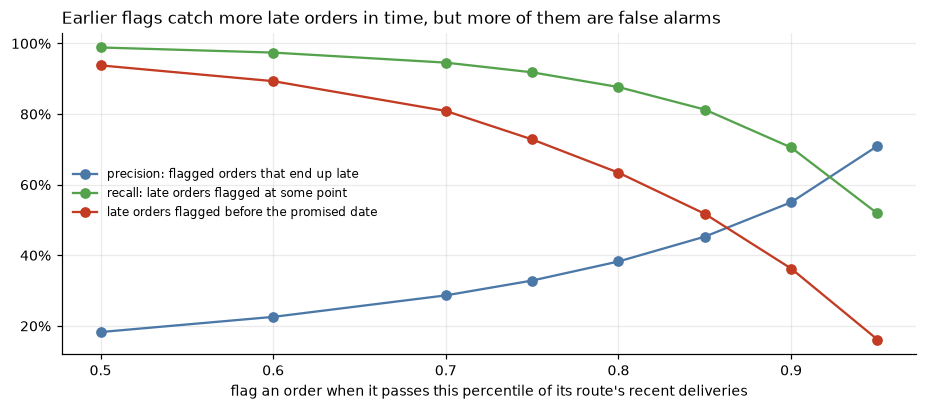

,flag at percentile,orders flagged %,flagged that end up late %,late orders caught %,caught before the deadline %,median days of warning
0,0.50,41.8,18.3,98.9,93.8,9.0
1,0.60,33.3,22.6,97.4,89.3,7.6
2,0.70,25.5,28.7,94.6,80.9,5.8
3,0.75,21.6,32.9,91.8,72.8,4.7
4,0.80,17.7,38.3,87.7,63.4,3.4
5,0.85,13.9,45.3,81.3,51.8,2.0
6,0.90,9.9,55.0,70.5,36.3,0.1
7,0.95,5.6,71.0,51.9,16.2,-2.8


In [8]:
late = ev["is_late"].to_numpy().astype(bool)
rows = []
for i, qq in enumerate(QUANTILES):
    threshold = Q[:, i]
    flagged = ev["delivery_days"].to_numpy() > threshold
    warning = ev["promised_days"].to_numpy() - threshold
    caught_late = flagged & late
    rows.append({
        "flag at percentile": qq,
        "orders flagged %": 100 * flagged.mean(),
        "flagged that end up late %": 100 * late[flagged].mean(),
        "late orders caught %": 100 * caught_late.sum() / late.sum(),
        "caught before the deadline %": 100 * (caught_late & (warning > 0)).sum() / late.sum(),
        "median days of warning": np.median(warning[caught_late]),
    })
curve = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.plot(curve["flag at percentile"], curve["flagged that end up late %"], marker="o", color="#4C78A8",
        label="precision: flagged orders that end up late")
ax.plot(curve["flag at percentile"], curve["late orders caught %"], marker="o", color="#54A24B",
        label="recall: late orders flagged at some point")
ax.plot(curve["flag at percentile"], curve["caught before the deadline %"], marker="o", color="#C23B22",
        label="late orders flagged before the promised date")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_xlabel("flag an order when it passes this percentile of its route's recent deliveries")
ax.set_title("Earlier flags catch more late orders in time, but more of them are false alarms", loc="left", fontsize=11)
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

curve.round(1).assign(**{"flag at percentile": curve["flag at percentile"]})

The trade-off is clear, and the middle of the range is useful.

Flagging at the **80th percentile** flags 17.7% of orders. 38% of the flagged orders end up late - five times the base rate of 7.7% - and the flag catches 88% of all late orders, almost two thirds of them before the promised date, with a median of 3.4 days' warning.

Moving to the 90th percentile makes the flag far more accurate, 55%, but most late orders are flagged only around the deadline itself. Moving to the 70th catches four in five late orders in time, with more false alarms.

There is no single right answer. It depends on the cost of contacting a customer whose order turns out fine against the value of warning one whose order does not, which is a business decision rather than an analytical one.

---

## 5. Could a model predict lateness at purchase?

A natural alternative is to predict lateness at the moment of purchase, with a model trained on everything known then: route, distance, parcel size, basket, payment method, product category, month and day of the week. This would give the most warning possible.

The model is a logistic regression trained on 2017 and tested on 2018. Splitting by time rather than at random is essential: a random split would let the model learn from orders placed after the ones it is being tested on.

In [9]:
ml = q("""
    SELECT order_id, is_late::INT AS y, purchase_date, promised_days, distance_km,
           COALESCE(GREATEST(weight_g, volume_cm3 / 6.0), 1365) AS billable_g,
           n_items, n_sellers,
           COALESCE(main_payment_type, 'unknown') AS payment,
           COALESCE(main_category, 'unknown')     AS category,
           COALESCE(seller_state, 'NA')           AS seller_state,
           COALESCE(customer_state, 'NA')         AS customer_state,
           month(purchase_date)                   AS month,
           dayofweek(purchase_date)               AS weekday
    FROM delivery
    WHERE distance_km IS NOT NULL
    ORDER BY order_id
""")

train = ml[ml["purchase_date"] <  pd.Timestamp("2018-01-01")]
test  = ml[ml["purchase_date"] >= pd.Timestamp("2018-01-01")]

numeric     = ["promised_days", "distance_km", "billable_g", "n_items", "n_sellers"]
categorical = ["payment", "category", "seller_state", "customer_state", "month", "weekday"]

model = make_pipeline(
    ColumnTransformer([
        ("num", StandardScaler(), numeric),
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=30), categorical),
    ]),
    LogisticRegression(max_iter=2000, class_weight="balanced"),
)
model.fit(train[numeric + categorical], train["y"])
p = model.predict_proba(test[numeric + categorical])[:, 1]

print(f"test AUC:               {roc_auc_score(test['y'], p):.3f}")
print(f"test average precision: {average_precision_score(test['y'], p):.3f}   (a random guess scores {test['y'].mean():.3f})")

test AUC:               0.681
test average precision: 0.151   (a random guess scores 0.077)


The model has real but limited skill: an AUC of 0.68, and an average precision about twice what a random guess would achieve.

The fairest comparison with the early warning is at the same number of flags.

In [10]:
ranked = test["y"].to_numpy()[np.argsort(-p)]
compare = []
for qq in [0.8, 0.85, 0.9]:
    row = curve[curve["flag at percentile"] == qq].iloc[0]
    k = int(len(ranked) * row["orders flagged %"] / 100)
    compare.append({
        "orders flagged %": row["orders flagged %"],
        "model at purchase: precision %": 100 * ranked[:k].mean(),
        "model at purchase: late caught %": 100 * ranked[:k].sum() / ranked.sum(),
        f"route flag: precision %": row["flagged that end up late %"],
        f"route flag: late caught %": row["late orders caught %"],
        f"route flag: caught before deadline %": row["caught before the deadline %"],
    })
pd.DataFrame(compare).round(1)

,orders flagged %,model at purchase: precision %,model at purchase: late caught %,route flag: precision %,route flag: late caught %,route flag: caught before deadline %
0,17.7,16.2,37.2,38.3,87.7,63.4
1,13.9,17.5,31.5,45.3,81.3,51.8
2,9.9,18.8,24.2,55.0,70.5,36.3


Flagging the same 17.7% of orders, the model's flags turn out late 16% of the time and catch 37% of late orders. The route flag at the 80th percentile is right 38% of the time and catches 88% - and even counting only flags raised before the deadline, it catches 63%, well ahead of the model.

The reason is the central finding of the delivery analysis. Lateness is driven mainly by what happens in transit, and at the moment of purchase that has not happened yet. A model at purchase is predicting an event whose main cause is still in the future. The route flag waits until the information exists, and then uses it.

The machine-learning approach is not useless - it gives the longest possible warning for the orders it does catch - but it is the weaker tool, and a percentile lookup that anyone can explain outperforms it.

---

## 6. Could the same baseline set a better promise?

If the expected times are good enough to judge orders, they could in principle replace the promise itself: give each order a promise equal to a high percentile of its route, chosen so that the overall late rate stays where it was. That would pad each route by its own uncertainty rather than by a fixed number of days.

The test uses the same rolling, leakage-free calculation on whole days, since a promise is a date.

In [11]:
Q_PROMISE = [round(x, 3) for x in np.arange(0.85, 0.991, 0.005)]
qp = ", ".join(str(x) for x in Q_PROMISE)

pb = q(f"""
    WITH base AS (
        SELECT *, date_diff('day', purchase_date, delivered_date) AS delivered_day FROM delivery),
    months AS (
        SELECT CAST(unnest(generate_series(DATE '2018-01-01', DATE '2018-08-01', INTERVAL 1 MONTH)) AS DATE) AS month),
    history AS (
        SELECT m.month, b.route_key, b.distance_band, b.delivered_day
        FROM months m JOIN base b
          ON b.delivered_date < m.month AND b.purchase_date >= m.month - INTERVAL 6 MONTH),
    by_route AS (SELECT month, route_key, quantile_cont(delivered_day, [{qp}]) AS q
                 FROM history GROUP BY 1, 2 HAVING COUNT(*) >= 30),
    by_band  AS (SELECT month, distance_band, quantile_cont(delivered_day, [{qp}]) AS q FROM history GROUP BY 1, 2),
    by_all   AS (SELECT month, quantile_cont(delivered_day, [{qp}]) AS q FROM history GROUP BY 1)
    SELECT b.order_id, b.purchase_date, b.distance_band, b.promised_days, b.is_late, b.delivered_day,
           COALESCE(r.q, d.q, a.q) AS q
    FROM base b
    JOIN by_all a       ON a.month = date_trunc('month', b.purchase_date)
    LEFT JOIN by_route r ON r.month = date_trunc('month', b.purchase_date) AND r.route_key = b.route_key
    LEFT JOIN by_band d  ON d.month = date_trunc('month', b.purchase_date) AND d.distance_band = b.distance_band
    WHERE b.purchase_date >= DATE '2018-01-01'
    ORDER BY b.order_id
""")

QP = np.ceil(np.vstack(pb["q"].to_numpy()))
actual_late = pb["is_late"].mean()
late_by_q = [(pb["delivered_day"].to_numpy() > QP[:, i]).mean() for i in range(len(Q_PROMISE))]
best = int(np.argmin([abs(l - actual_late) for l in late_by_q]))
pb["rule_promise"] = QP[:, best]
pb["rule_late"] = pb["delivered_day"] > pb["rule_promise"]

print(f"percentile that matches Olist's late rate: {Q_PROMISE[best]}")
print(f"Olist's promise: {pb['promised_days'].mean():.1f} days, late {100 * actual_late:.2f}%")
print(f"route rule:      {pb['rule_promise'].mean():.1f} days, late {100 * pb['rule_late'].mean():.2f}%")

summary = pb[pb["distance_band"] > 0].groupby("distance_band").agg(
    orders=("rule_promise", "size"),
    olist_promise=("promised_days", "mean"), rule_promise=("rule_promise", "mean"),
    olist_late_pct=("is_late", lambda s: 100 * s.mean()), rule_late_pct=("rule_late", lambda s: 100 * s.mean()))
summary.index = summary.index.map(BAND_NAMES)
summary.round(2)

percentile that matches Olist's late rate: 0.92
Olist's promise: 23.4 days, late 7.73%
route rule:      23.7 days, late 7.65%


,orders,olist_promise,rule_promise,olist_late_pct,rule_late_pct
distance_band,,,,,
under 200 km,14485,15.74,16.12,4.93,4.61
200-500 km,16417,23.97,23.15,7.34,8.69
500-1000 km,13646,26.65,26.75,8.55,8.76
1000-2000 km,5040,30.01,31.80,10.69,8.12
2000 km and over,2936,32.18,36.42,14.41,10.66


In [12]:
pb["month"] = pb["purchase_date"].dt.strftime("%Y-%m")
pb.groupby("month").agg(
    olist_promise=("promised_days", "mean"), rule_promise=("rule_promise", "mean"),
    olist_late_pct=("is_late", lambda s: 100 * s.mean()), rule_late_pct=("rule_late", lambda s: 100 * s.mean())
).round(2)

,olist_promise,rule_promise,olist_late_pct,rule_late_pct
month,,,,
2018-01,26.94,20.51,5.70,13.79
2018-02,25.16,22.94,14.13,17.12
2018-03,22.67,23.40,18.96,17.09
2018-04,24.31,24.66,4.50,3.25
2018-05,23.53,26.05,6.56,3.22
2018-06,28.41,25.19,1.16,1.66
2018-07,20.33,24.87,3.38,2.13
2018-08,15.82,22.53,6.19,1.15


The route rule does not beat Olist's promise overall. Matched to the same late rate, its promises are slightly *longer* on average, 23.7 days against 23.4.

What it changes is who carries the risk. On routes beyond 2,000 km the late rate falls from 14.4% to 10.7%, and from 10.7% to 8.1% at 1,000–2,000 km, paid for with longer promises on those routes and a slightly higher late rate on middle-distance ones. Reliability becomes more even across the country.

The monthly table shows its weakness. In January 2018 the rule promised 20.5 days, having learned from a calm second half of 2017, and was late on 13.8% of orders. Olist promised 26.9 days, anticipating post-holiday congestion that the history did not contain, and was late on 5.7%. A rule built only from past deliveries cannot foresee a shock that has not happened yet; Olist's own promise evidently includes judgement about what is coming.

So the evidence does not support replacing Olist's promise with a statistical one. It supports a narrower change: padding long routes by their own uncertainty rather than by the same number of days as everywhere else.

---

## 7. What to do with a flagged order

An early warning is only useful if there is something worth doing when it fires. The obvious response, a discount to win the customer back, rests on an assumption that can be tested: that a late delivery costs Olist the customer's future business.

In [13]:
show("""
    WITH customer_orders AS (
        SELECT dc.customer_unique_id AS customer, o.order_id, o.purchase_ts, o.is_delivered, o.is_late,
               ROW_NUMBER() OVER (PARTITION BY dc.customer_unique_id ORDER BY o.purchase_ts, o.order_id) AS nth
        FROM clean.orders o JOIN model.dim_customer dc USING (customer_id))
    SELECT COUNT(DISTINCT customer)                                              AS customers,
           ROUND(100.0 * COUNT(DISTINCT customer) FILTER (WHERE nth = 2)
                 / COUNT(DISTINCT customer), 2)                                  AS pct_with_a_second_order
    FROM customer_orders
""")

repeat = q("""
    WITH customer_orders AS (
        SELECT dc.customer_unique_id AS customer, o.order_id, o.purchase_ts, o.is_delivered, o.is_late,
               ROW_NUMBER() OVER (PARTITION BY dc.customer_unique_id ORDER BY o.purchase_ts, o.order_id) AS nth
        FROM clean.orders o JOIN model.dim_customer dc USING (customer_id)),
    first_orders AS (
        SELECT * FROM customer_orders
        WHERE nth = 1 AND is_delivered
          AND CAST(purchase_ts AS DATE) BETWEEN DATE '2017-01-01' AND DATE '2018-02-28'),
    outcome AS (
        SELECT f.is_late,
               (s.purchase_ts IS NOT NULL AND s.purchase_ts <= f.purchase_ts + INTERVAL 180 DAY) AS came_back
        FROM first_orders f
        LEFT JOIN customer_orders s ON s.customer = f.customer AND s.nth = 2)
    SELECT CASE WHEN is_late THEN 'first order late' ELSE 'first order on time' END AS first_order,
           COUNT(*)                                     AS customers,
           SUM(came_back::INT)                          AS ordered_again_within_180_days,
           ROUND(100.0 * AVG(came_back::INT), 2)        AS pct
    FROM outcome GROUP BY 1 ORDER BY 1
""")
repeat

┌───────────┬─────────────────────────┐
│ customers │ pct_with_a_second_order │
│   int64   │         double          │
├───────────┼─────────────────────────┤
│     96096 │                    3.12 │
└───────────┴─────────────────────────┘



,first_order,customers,ordered_again_within_180_days,pct
0,first order late,3664,98.0,2.67
1,first order on time,51532,1657.0,3.22


In [14]:
late_row = repeat[repeat["first_order"] == "first order late"].iloc[0]
ok_row   = repeat[repeat["first_order"] == "first order on time"].iloc[0]
late_n, late_k = late_row["customers"], late_row["ordered_again_within_180_days"]
ok_n,   ok_k   = ok_row["customers"],   ok_row["ordered_again_within_180_days"]
p1, p2 = late_k / late_n, ok_k / ok_n
pooled = (late_k + ok_k) / (late_n + ok_n)
z = (p1 - p2) / np.sqrt(pooled * (1 - pooled) * (1 / late_n + 1 / ok_n))
print(f"difference: {100 * (p1 - p2):+.2f} percentage points, z = {z:.2f}")

difference: -0.54 percentage points, z = -1.80


Only 3.1% of Olist's customers ever place a second order. Each first order is followed for exactly 180 days, using only first orders placed early enough for that full window to fit in the data. On that basis, customers whose first order was late came back 2.67% of the time against 3.22% for those whose order was on time. The gap of about half a percentage point is suggestive but falls short of statistical significance (z = −1.80). Even taken at face value, it amounts to about 20 lost repeat customers among the 3,664 whose first order was late.

Olist is essentially a one-shot marketplace, and a late delivery changes that only slightly, if at all. A discount aimed at winning back a customer who was never likely to return has very little to work with.

The damage from a late order is elsewhere: in a public review that the next buyer reads. And the delivery analysis showed what drives most of those reviews - 83.6% of reviews on late orders are written before the parcel arrives, because the survey is sent on the estimated delivery date, and half of their comments say the product has not come.

That points to two responses, in order of how well the data supports them.

1. **Send the review request when the parcel is delivered**, not on the estimated date. Late orders reviewed after arrival average 3.78 stars against 1.97 for those reviewed before. This needs no prediction at all.
2. **Use the early warning to tell customers before the deadline that their order is running late.** The data cannot show whether this improves reviews, because Olist did not do it during this period, so it would need to be tested - for example on a random half of flagged orders.

A discount for every flagged order is not supported by this data.

---

## 8. Saving the results for the dashboard

The expected times and flags are saved for every order from July 2017, so the dashboard can show orders that were slower than normal for their route alongside the late rate.

In [15]:
con.sql(f"""
    CREATE OR REPLACE TABLE model.fct_order_baseline AS
    SELECT
        b.order_id,
        b.baseline_month,
        b.baseline_level,
        ROUND(b.q[{QUANTILES.index(0.5) + 1}], 2)  AS expected_days_p50,
        ROUND(b.q[{QUANTILES.index(0.8) + 1}], 2)  AS warning_threshold_p80,
        ROUND(b.q[{QUANTILES.index(0.9) + 1}], 2)  AS slow_threshold_p90,
        v.delivery_days,
        ROUND(v.delivery_days - b.q[{QUANTILES.index(0.5) + 1}], 2) AS days_vs_expected,
        v.delivery_days > b.q[{QUANTILES.index(0.9) + 1}]           AS slower_than_normal,
        v.delivery_days > b.q[{QUANTILES.index(0.8) + 1}]           AS would_have_been_flagged,
        v.promised_days > b.q[{QUANTILES.index(0.8) + 1}]           AS flag_before_deadline
    FROM model.order_delivery_baseline b
    JOIN delivery v USING (order_id)
""")

out = "../outputs/model"
os.makedirs(out, exist_ok=True)
con.sql("SELECT * FROM model.fct_order_baseline").df().to_csv(f"{out}/fct_order_baseline.csv", index=False)

show("""
    SELECT COUNT(*) AS orders,
           ROUND(100 * AVG(slower_than_normal::INT), 2)      AS pct_slower_than_normal,
           ROUND(100 * AVG(would_have_been_flagged::INT), 2) AS pct_flagged
    FROM model.fct_order_baseline
""")

┌────────┬────────────────────────┬─────────────┐
│ orders │ pct_slower_than_normal │ pct_flagged │
│ int64  │         double         │   double    │
├────────┼────────────────────────┼─────────────┤
│  82271 │                  12.77 │       21.77 │
└────────┴────────────────────────┴─────────────┘



---

## 9. What this analysis establishes

**A useful definition of "slow" has to be route-specific and has to describe spread.** Olist pads every distance band by about the same number of days while delivery uncertainty doubles with distance, so short routes are over-protected and long routes under-protected. A percentile of each route's recent deliveries solves both problems.

**Judging orders against their route finds problems the late rate cannot see.** In 2018, 2,351 orders were slower than normal for their route but on time, and customers rated them about 0.45 stars lower whether they arrived on the deadline or eleven days early. Another 1,201 late orders - 29% of the total - were normal for their route; the promise, not the delivery, was the problem.

**The same baseline is an effective early warning.** Flagging orders still in transit at the 80th percentile of their route flags 17.7% of orders, 38% of which end up late, and catches 88% of late orders - 63% before the promised date, with a median 3.4 days' warning. The threshold can be moved to trade accuracy against warning time.

**It beats a machine-learning model built for the task.** A model predicting lateness at purchase reaches an AUC of 0.68 but, flagging the same number of orders, catches 37% of late orders with 16% precision. Lateness is mostly decided in transit, after the moment of purchase.

**Olist's promise holds up against a statistical rule.** A route-percentile promise matched to the same late rate is no shorter, fails badly after the 2017 holidays, and only redistributes reliability towards long routes. The case is for padding long routes by their uncertainty, not for replacing the promise.

**The right response to a flag is information, not discounts.** Only 3.1% of customers ever order twice, and a late first order lowers that by about half a percentage point at most. Sending the review request on delivery is supported directly by the data; warning customers in advance is promising but would need to be tested; blanket discounts are not supported.

In [16]:
con.close()
print("connection closed")

connection closed
